# 第095讲可执行实验

先阅读lecture.md与lab.md，再重启内核从上到下执行。所有数据本地合成；不调用网络、GPU或付费模型。输出会覆盖本讲可再生的outputs/figures；探索实验请复制目录。

## 1 核对环境与工作目录
Notebook依赖同目录experiment.py。不要只下载.ipynb。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
ROOT = Path.cwd()
assert (ROOT / "experiment.py").exists(), "请切换到本讲目录"
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)

Python: 3.12.14 NumPy: 2.3.5


## 2 阅读实现并形成预测
下面列出核心实验源码。先对照讲义找出数据生成、模型或解析场、积分与评价四个位置。代码内注释解释形状、方向与边界。

In [2]:
import inspect
import experiment
print(inspect.getsource(experiment))

"""原创 CPU 教学实验。运行 python experiment.py；无需网络、GPU 或模型下载。"""
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/dl-mpl")
import json, time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ROOT = Path(__file__).resolve().parent
OUT = ROOT / "outputs"
FIG = ROOT / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=160); plt.close()

def velocity(x, t, grid, coefficients):
    # 每个时间箱的线性回归给出 a(t), b(t)，插值避免时间箱边界跳跃。
    a = np.interp(t, grid, coefficients[:, 0])
    b = np.interp(t, grid, coefficients[:, 1])
    return a*x+b

def integrate(z, steps, grid, coefficients):
    x=z.copy(); h=1.0/steps
    for k in range(steps):
        # 显式 Euler；本讲故意保留一阶误差，以供步长消融。
        x += h*velocity(x, k*h, grid, coefficients)
    return x

def main():
    rng=np.random.default_rng(95)
    grid=np.linspace(0,1,51); rows=[]; training=[]
    mu=2.0; sigma=0.7
 

## 3 从头重新运行实验
这会真实生成样本、计算指标并重建图形；不是展示缓存结果。

In [3]:
results = experiment.main()

{
  "seed": 95,
  "training_pairs": 102000,
  "target_mean": 2.0,
  "target_std": 0.7,
  "steps": {
    "10": {
      "mean": 1.9877370632518883,
      "std": 0.6190350661211865,
      "paired_affine_rmse": 0.08917793464039027,
      "central_95_coverage": 0.9699
    },
    "40": {
      "mean": 1.9992595424626771,
      "std": 0.6878940190838302,
      "paired_affine_rmse": 0.019599503734178268,
      "central_95_coverage": 0.953
    },
    "160": {
      "mean": 1.9999203151479763,
      "std": 0.7053126215418386,
      "paired_affine_rmse": 0.002346792828942579,
      "central_95_coverage": 0.9466
    }
  }
}


## 4 核对持久化证据
先看每个数组的形状与是否有限，再解释指标。

In [4]:
saved = json.loads((ROOT / "outputs/metrics.json").read_text())
print(json.dumps(saved, ensure_ascii=False, indent=2))
with np.load(ROOT / "outputs/data.npz") as data:
    for key in data.files:
        a = data[key]
        print(key, a.shape, "finite:", bool(np.isfinite(a).all()))

{
  "seed": 95,
  "training_pairs": 102000,
  "target_mean": 2.0,
  "target_std": 0.7,
  "steps": {
    "10": {
      "mean": 1.9877370632518883,
      "std": 0.6190350661211865,
      "paired_affine_rmse": 0.08917793464039027,
      "central_95_coverage": 0.9699
    },
    "40": {
      "mean": 1.9992595424626771,
      "std": 0.6878940190838302,
      "paired_affine_rmse": 0.019599503734178268,
      "central_95_coverage": 0.953
    },
    "160": {
      "mean": 1.9999203151479763,
      "std": 0.7053126215418386,
      "paired_affine_rmse": 0.002346792828942579,
      "central_95_coverage": 0.9466
    }
  }
}
base (10000,) finite: True
affine (10000,) finite: True
coefficients (51, 2) finite: True
grid (51,) finite: True
flow_10 (10000,) finite: True
flow_40 (10000,) finite: True
flow_160 (10000,) finite: True
affine_log_density (10000,) finite: True


## 5 看完整图，不挑漂亮样本
图与讲义对应。观察不符合直觉的地方，结合指标解释。

01_velocity.png


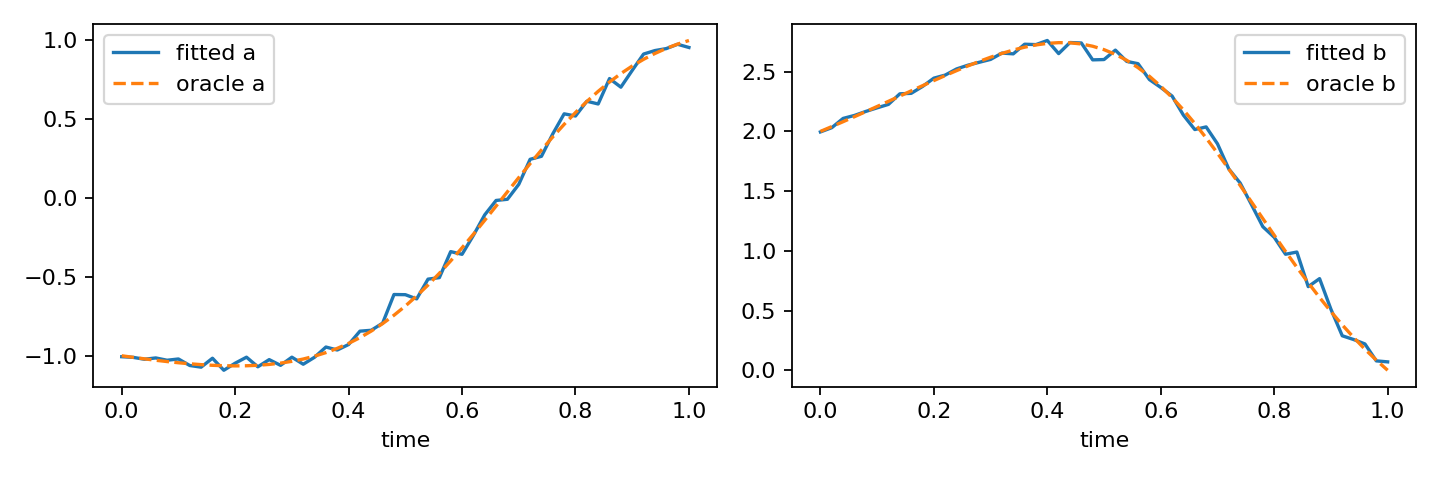

02_distribution.png


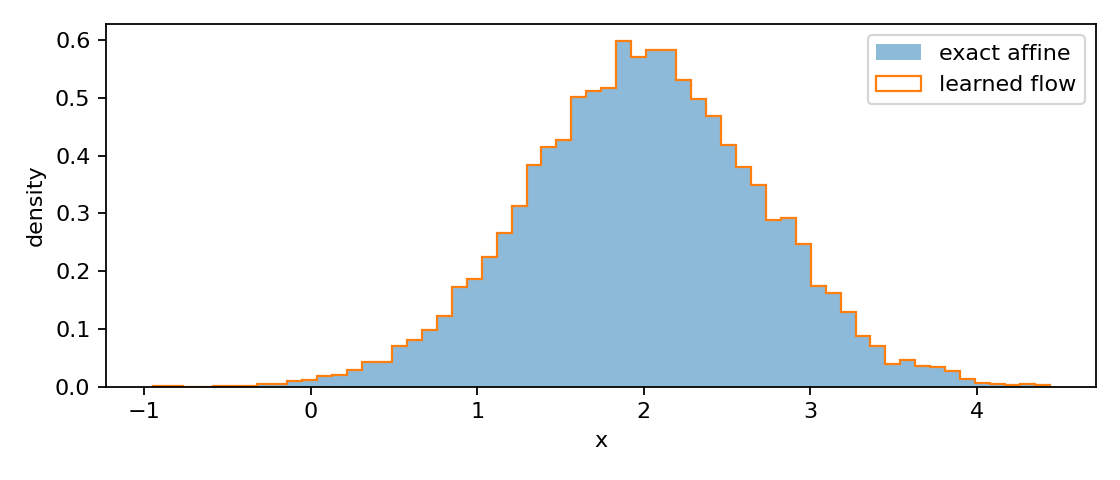

03_paths.png


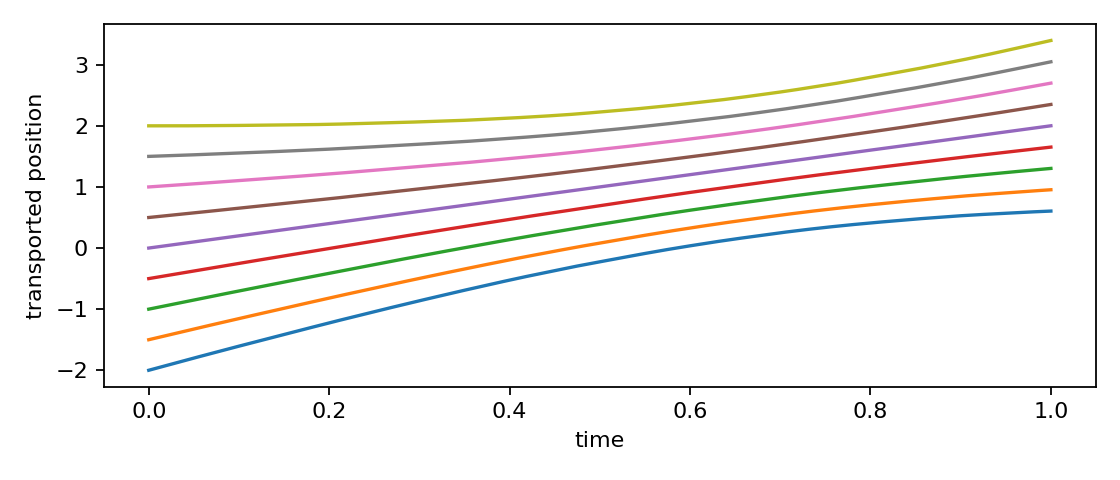

In [5]:
from IPython.display import display, Image
for figure in sorted((ROOT / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=str(figure), width=760))

## 6 执行独立断言
测试通过只覆盖这些明确断言，不等于现实部署验证。之后按lab.md做一个受控变化。

In [6]:
import unittest
import tests
suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_affine_reference (tests.TestExperiment.test_affine_reference) ... 

ok


test_constant_velocity (tests.TestExperiment.test_constant_velocity) ... 

ok


test_density_normalizes (tests.TestExperiment.test_density_normalizes) ... 

...

test_output (tests.TestExperiment.test_output) ... 

ok


test_velocity_endpoints (tests.TestExperiment.test_velocity_endpoints) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.028s

OK


## 反思与交付
写清本实验是学习模型还是解析score、样本数和种子、主要误差来源、实际结果与未检验范围。练习详解见answers.md。